In [7]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

Two Moons erzeugen:
X enthält die Koordinaten.
y enthält die Klassenlabels 0 und 1.
80 % der Daten werden zum Trainieren verwendet.
20 % bleiben für den späteren Test zurück.

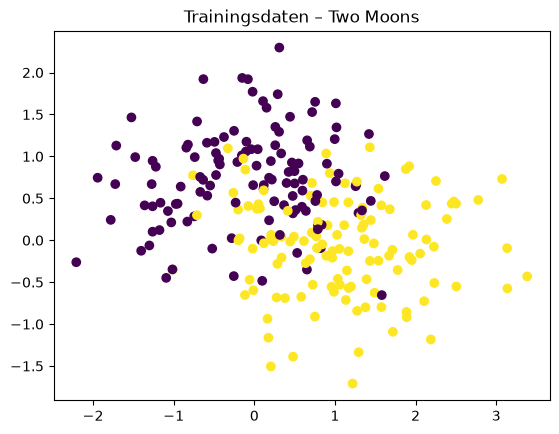

In [8]:
X, y = make_moons(n_samples=300, noise=0.5, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train)
plt.title("Trainingsdaten – Two Moons")
plt.show()

6 ML-Modelle erzeugen, mit folgenden wichtigen Parametern: 
- max_depth=5: Der Entscheidungsbaum darf maximal fünf Ebenen tief werden.
- n_estimators=100: Der Random Forest verwendet 100 Entscheidungsbäume.
- kernel="rbf": Die SVM kann nichtlineare Grenzen lernen.
- hidden_layer_sizes=(20, 20): Das neuronale Netz hat zwei versteckte Schichten mit jeweils 20 Neuronen.
- RBF(...): Der Gaußprozess verwendet einen Kernel, der die Ähnlichkeit von Datenpunkten anhand ihrer Entfernung beschreibt.
- StandardScaler(): Standardisiert die Merkmale, was für einige Modelle besonders wichtig ist.

In [9]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(random_state=42)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=42)),
    "Neural Network": make_pipeline(
        StandardScaler(), MLPClassifier(hidden_layer_sizes=(20, 20), max_iter=2000, random_state=42)
    ),
    "Gaussian Process": make_pipeline(
        StandardScaler(), GaussianProcessClassifier(kernel=1.0 * RBF(length_scale=1.0), random_state=42)
    ),
}

Modelle trainieren und vergleichen:

In [10]:
for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    print(f"{name}: {accuracy:.2%}")

Logistic Regression: 71.67%
Decision Tree: 78.33%
Random Forest: 71.67%
SVM: 71.67%
Neural Network: 71.67%
Gaussian Process: 71.67%


Modelle visualisieren

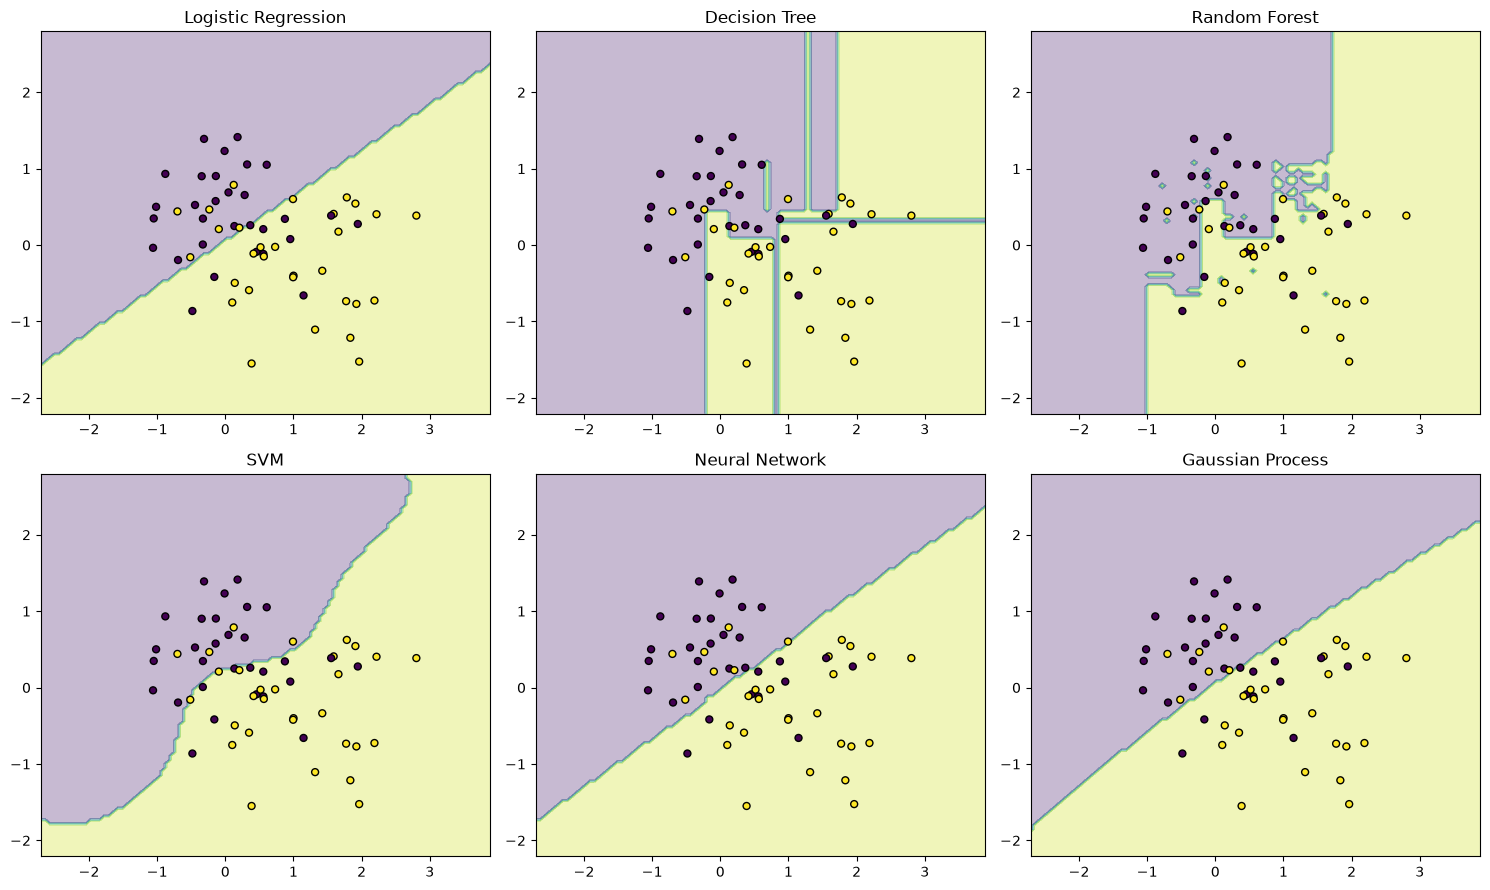

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

grid = np.c_[xx.ravel(), yy.ravel()]

for ax, (name, model) in zip(axes.ravel(), models.items()):
    predictions = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, predictions, alpha=0.3)

    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolors="black", s=25)

    ax.set_title(name)

plt.tight_layout()
plt.show()